In [ ]:
# Лабораторная работа 1. Царегородцева ИСТ-47
## Шаг 1. Загрузка данных
## Шаг 2. Предобработка
## Шаг 3. Функции активации
## Шаг 4. Класс MLP
## Шаг 5. Обучение
## Шаг 6. Оценка на тесте
## Шаг 7. Baseline (Logistic Regression)
## Шаг 8. Бонус: анализ ошибок

# Шаг 1.1. Импорты и настройка
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, RocCurveDisplay
)

np.random.seed(42)
print("Импорты загружены")

Импорты загружены


In [ ]:
# Шаг 1.2. Загрузка Cleveland Heart Disease Dataset
DATA_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)

COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]

raw = pd.read_csv(DATA_URL, header=None, names=COLUMNS, na_values="?")
print(f"Размер датасета (до очистки): {raw.shape}")
raw.head()

Размер датасета (до очистки): (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [ ]:
# Задание 1.1. Изучение датасета
print("=== info() ===")
raw.info()

print("\n=== Пропуски по столбцам ===")
print(raw.isnull().sum())

print("\n=== Распределение target (до бинаризации, 0-4) ===")
print(raw["target"].value_counts().sort_index())

print("\n=== Доля классов после бинаризации (предварительно) ===")
tmp = (raw["target"] > 0).astype(int)
print(tmp.value_counts(normalize=True).round(3))

=== info() ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

=== Пропуски по столбцам ===
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal  

In [ ]:
# Шаг 1.3. Удаление пропусков и бинаризация target
raw = raw.dropna()
print(f"Размер после удаления пропусков: {raw.shape}")

raw["target"] = (raw["target"] > 0).astype(int)
print("\nРаспределение бинарного target:")
print(raw["target"].value_counts(normalize=True).round(3))

Размер после удаления пропусков: (297, 14)

Распределение бинарного target:
target
0    0.539
1    0.461
Name: proportion, dtype: float64


In [ ]:
# Задание 2.1. Предобработка: нормализация + one-hot
def preprocess_data(df):
    df = df.copy()
    y = df["target"].values.astype(np.int64)

    numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
    categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

    X_num = df[numeric_cols].values.astype(np.float64)

    # >>> ЗАДАНИЕ 2.1 <<<
    X_cat = pd.get_dummies(df[categorical_cols], drop_first=True)
    # <<< КОНЕЦ ЗАДАНИЯ >>>

    X = np.hstack([X_num, X_cat.values]).astype(np.float64)
    return X, y, numeric_cols

X, y, numeric_cols = preprocess_data(raw)
print(f"X.shape = {X.shape}")
print(f"y.shape = {y.shape}")
print(f"numeric_cols = {numeric_cols}")

X_cat_check = pd.get_dummies(raw[["sex","cp","fbs","restecg","exang","slope","ca","thal"]], drop_first=True)
print("Столбцы one-hot:")
print(list(X_cat_check.columns))
print("Всего:", X_cat_check.shape[1])

X.shape = (297, 13)
y.shape = (297,)
numeric_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Столбцы one-hot:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
Всего: 8


In [ ]:
# Шаг 2.2. Train / Val / Test split (70 / 15 / 15)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")
print(f"Train баланс: {np.bincount(y_train) / len(y_train)}")
print(f"Val баланс:   {np.bincount(y_val) / len(y_val)}")
print(f"Test баланс:  {np.bincount(y_test) / len(y_test)}")

Train: (207, 13), Val: (45, 13), Test: (45, 13)
Train баланс: [0.5410628 0.4589372]
Val баланс:   [0.53333333 0.46666667]
Test баланс:  [0.53333333 0.46666667]


In [ ]:
# Задание 2.2. Нормализация числовых признаков (fit только на train!)
scaler = StandardScaler()
num_features = len(numeric_cols)  # 5

# >>> ЗАДАНИЕ 2.2 <<<
scaler.fit(X_train[:, :num_features])

X_train[:, :num_features] = scaler.transform(X_train[:, :num_features])
X_val[:, :num_features]   = scaler.transform(X_val[:, :num_features])
X_test[:, :num_features]  = scaler.transform(X_test[:, :num_features])
# <<< КОНЕЦ ЗАДАНИЯ >>>

print("Средние на train (числ. признаки):", X_train[:, :num_features].mean(axis=0).round(3))
print("Стд на train (числ. признаки):    ", X_train[:, :num_features].std(axis=0).round(3))
print("Средние на val (числ. признаки):  ", X_val[:, :num_features].mean(axis=0).round(3))

Средние на train (числ. признаки): [-0.  0.  0. -0.  0.]
Стд на train (числ. признаки):     [1. 1. 1. 1. 1.]
Средние на val (числ. признаки):   [ 0.17   0.07  -0.077 -0.206 -0.11 ]


In [ ]:
# Шаг 2.4. One-hot для меток (для cross-entropy)
def to_one_hot(y, num_classes=2):
    m = y.shape[0]
    one_hot = np.zeros((m, num_classes))
    one_hot[np.arange(m), y] = 1
    return one_hot

y_train_oh = to_one_hot(y_train)
y_val_oh = to_one_hot(y_val)

print("y_train[:5]     =", y_train[:5])
print("y_train_oh[:5] =\n", y_train_oh[:5])

y_train[:5]     = [0 0 0 1 0]
y_train_oh[:5] =
 [[1. 0.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [1. 0.]]


In [ ]:
# Шаг 3. Функции активации
def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

def softmax(z):
    """z: (batch_size, num_classes) -> вероятности классов"""
    # >>> ЗАДАНИЕ 3.1 <<<
    z_shifted = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z_shifted)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)
    # <<< КОНЕЦ ЗАДАНИЯ >>>

# Проверка softmax
test_z = np.array([[1.0, 2.0, 3.0], [1.0, 1.0, 1.0]])
probs = softmax(test_z)
print(probs)
assert np.allclose(probs.sum(axis=1), 1.0), "Softmax: сумма по строке должна быть 1"
print("Softmax OK")

# Проверка relu
print("relu([-1, 0, 2]) =", relu(np.array([-1, 0, 2])))
print("relu'( [-1, 0, 2]) =", relu_derivative(np.array([-1, 0, 2])))

[[0.09003057 0.24472847 0.66524096]
 [0.33333333 0.33333333 0.33333333]]
Softmax OK
relu([-1, 0, 2]) = [0 0 2]
relu'( [-1, 0, 2]) = [0. 0. 1.]


In [ ]:
# Шаг 4. Класс MLP
class MLP:
    def __init__(self, input_size, hidden_size, output_size, learning_rate=0.01):
        self.lr = learning_rate
        # He-инициализация — оптимальна для ReLU
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
        self.b2 = np.zeros((1, output_size))

    def forward(self, X):
        self.X = X  # сохраняем для backward
        self.z1 = X @ self.W1 + self.b1
        self.a1 = relu(self.z1)
        self.z2 = self.a1 @ self.W2 + self.b2
        self.a2 = softmax(self.z2)
        return self.a2

    def compute_loss(self, y_pred, y_true):
        m = y_true.shape[0]
        # >>> ЗАДАНИЕ 4.1 <<<
        epsilon = 1e-9
        loss = -np.sum(y_true * np.log(y_pred + epsilon)) / m
        # <<< КОНЕЦ ЗАДАНИЯ >>>
        return loss

    def backward(self, X, y_true):
        m = X.shape[0]

        # Градиент на выходном слое (softmax + cross-entropy)
        dz2 = self.a2 - y_true                  # (m, output_size)
        dW2 = (self.a1.T @ dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        # Градиент через скрытый слой
        da1 = dz2 @ self.W2.T
        dz1 = da1 * relu_derivative(self.z1)

        # >>> ЗАДАНИЕ 4.2 <<<
        dW1 = (X.T @ dz1) / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m
        # <<< КОНЕЦ ЗАДАНИЯ >>>

        # Обновление весов (SGD)
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2

    def predict(self, X):
        probs = self.forward(X)
        return np.argmax(probs, axis=1)

    def predict_proba(self, X):
        return self.forward(X)[:, 1]

# Проверка MLP на синтетических данных
np.random.seed(0)
m_test = MLP(input_size=X_train.shape[1], hidden_size=8, output_size=2, learning_rate=0.1)

probs = m_test.forward(X_train[:5])
print("Форма выхода forward:", probs.shape)      # должно быть (5, 2)
print("Сумма по строке:", probs.sum(axis=1))      # все ≈ 1.0
print("Loss:", m_test.compute_loss(probs, y_train_oh[:5]))

Форма выхода forward: (5, 2)
Сумма по строке: [1. 1. 1. 1. 1.]
Loss: 3.2282780315819117


Epoch    0 | Loss: 0.9418 | Val AUC: 0.6706
Epoch   50 | Loss: 0.3524 | Val AUC: 0.8571
Epoch  100 | Loss: 0.3320 | Val AUC: 0.8175
Epoch  150 | Loss: 0.2239 | Val AUC: 0.8413
Epoch  200 | Loss: 0.1811 | Val AUC: 0.8056
Epoch  250 | Loss: 0.1727 | Val AUC: 0.8056
Epoch  300 | Loss: 0.1560 | Val AUC: 0.7817
Epoch  350 | Loss: 0.1871 | Val AUC: 0.7321
Epoch  400 | Loss: 0.1296 | Val AUC: 0.7738
Epoch  450 | Loss: 0.1608 | Val AUC: 0.7639


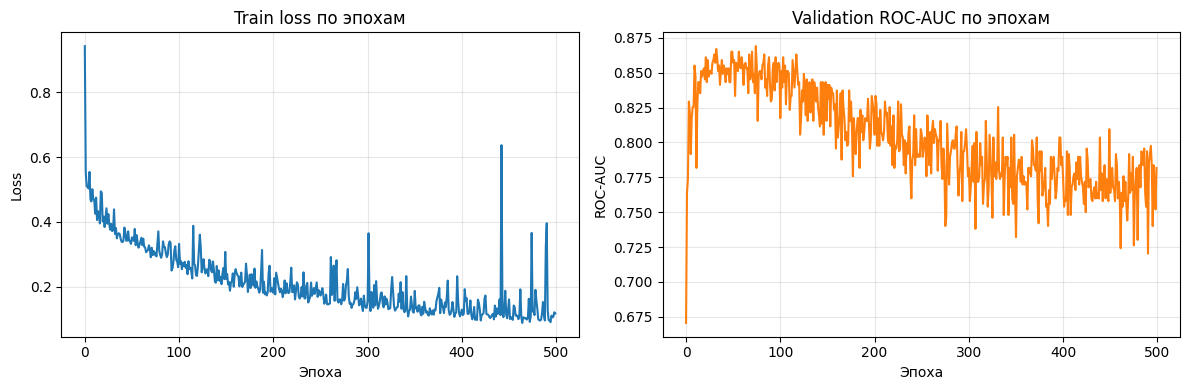


--- hidden_size=8, lr=0.1 ---
Val AUC = 0.6687 | Test AUC = 0.9504

--- hidden_size=16, lr=0.1 ---
Val AUC = 0.7817 | Test AUC = 0.9365

--- hidden_size=32, lr=0.05 ---
Val AUC = 0.7560 | Test AUC = 0.9663

--- hidden_size=64, lr=0.05 ---
Val AUC = 0.7639 | Test AUC = 0.9623

--- hidden_size=16, lr=0.01 ---
Val AUC = 0.8770 | Test AUC = 0.9901

=== Итоговая таблица ===
 hidden_size  learning_rate  Val AUC  Test AUC
           8           0.10   0.6687    0.9504
          16           0.10   0.7817    0.9365
          32           0.05   0.7560    0.9663
          64           0.05   0.7639    0.9623
          16           0.01   0.8770    0.9901
Epoch    0 | Loss: 1.3916 | Val AUC: 0.6508
Epoch   50 | Loss: 0.3751 | Val AUC: 0.7798
Epoch  100 | Loss: 0.3287 | Val AUC: 0.7817
Epoch  150 | Loss: 0.2776 | Val AUC: 0.7480
Epoch  200 | Loss: 0.2403 | Val AUC: 0.7560
Epoch  250 | Loss: 0.2194 | Val AUC: 0.7619
Epoch  300 | Loss: 0.1480 | Val AUC: 0.7659
Epoch  350 | Loss: 0.1250 | Val AUC: 

In [ ]:
# Шаг 5.1. Функция обучения
def train_mlp(model, X_train, y_train_oh, X_val, y_val,
              epochs=500, batch_size=32, verbose=True):
    history = {"train_loss": [], "val_auc": []}
    m = X_train.shape[0]

    for epoch in range(epochs):
        # Перемешиваем каждый эпоху
        indices = np.random.permutation(m)
        X_shuffled = X_train[indices]
        y_shuffled = y_train_oh[indices]

        epoch_loss = 0.0
        num_batches = 0

        # Mini-batch SGD
        for start in range(0, m, batch_size):
            X_batch = X_shuffled[start:start + batch_size]
            y_batch = y_shuffled[start:start + batch_size]

            y_pred = model.forward(X_batch)
            loss = model.compute_loss(y_pred, y_batch)
            model.backward(X_batch, y_batch)

            epoch_loss += loss
            num_batches += 1

        avg_loss = epoch_loss / num_batches
        val_probs = model.predict_proba(X_val)
        val_auc = roc_auc_score(y_val, val_probs)

        history["train_loss"].append(avg_loss)
        history["val_auc"].append(val_auc)

        if verbose and epoch % 50 == 0:
            print(f"Epoch {epoch:4d} | Loss: {avg_loss:.4f} | Val AUC: {val_auc:.4f}")

    return history

# Шаг 5.2. Обучение базовой модели
np.random.seed(42)
model = MLP(input_size=X_train.shape[1], hidden_size=16, output_size=2, learning_rate=0.1)

history = train_mlp(model, X_train, y_train_oh, X_val, y_val,
                    epochs=500, batch_size=32, verbose=True)

# Задание 5.1. Графики обучения
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], color="tab:blue")
axes[0].set_title("Train loss по эпохам")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)

axes[1].plot(history["val_auc"], color="tab:orange")
axes[1].set_title("Validation ROC-AUC по эпохам")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("ROC-AUC")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Задание 5.2. Подбор гиперпараметров
configs = [
    (8, 0.1),
    (16, 0.1),
    (32, 0.05),
    (64, 0.05),
    (16, 0.01),
]

results = []
for hidden_size, lr in configs:
    print(f"\n--- hidden_size={hidden_size}, lr={lr} ---")
    np.random.seed(42)
    m_exp = MLP(input_size=X_train.shape[1], hidden_size=hidden_size,
                output_size=2, learning_rate=lr)
    hist = train_mlp(m_exp, X_train, y_train_oh, X_val, y_val,
                     epochs=500, batch_size=32, verbose=False)

    val_auc = roc_auc_score(y_val, m_exp.predict_proba(X_val))
    test_auc = roc_auc_score(y_test, m_exp.predict_proba(X_test))
    results.append({
        "hidden_size": hidden_size,
        "learning_rate": lr,
        "Val AUC": round(val_auc, 4),
        "Test AUC": round(test_auc, 4),
    })
    print(f"Val AUC = {val_auc:.4f} | Test AUC = {test_auc:.4f}")

results_df = pd.DataFrame(results)
print("\n=== Итоговая таблица ===")
print(results_df.to_string(index=False))

# Переобучение финальной модели (пример: 32, 0.05 — замени на своё лучшее)
np.random.seed(42)
final_model = MLP(input_size=X_train.shape[1], hidden_size=32, output_size=2, learning_rate=0.05)
final_history = train_mlp(final_model, X_train, y_train_oh, X_val, y_val,
                          epochs=500, batch_size=32, verbose=True)



=== MLP — Test Metrics ===
Accuracy:  0.8222
Precision: 0.8095
Recall:    0.8095
F1:        0.8095
ROC-AUC:   0.9663

Confusion Matrix:
[[20  4]
 [ 4 17]]


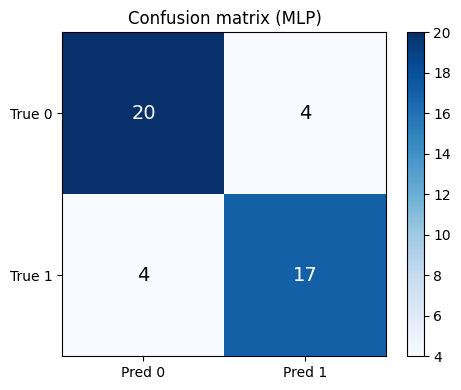

In [ ]:
# Шаг 6. Оценка финальной модели на тестовой выборке
y_test_pred  = final_model.predict(X_test)
y_test_proba = final_model.predict_proba(X_test)

print("=== MLP — Test Metrics ===")
print(f"Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_test_pred):.4f}")
print(f"F1:        {f1_score(y_test, y_test_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_test_proba):.4f}")

cm = confusion_matrix(y_test, y_test_pred)
print("\nConfusion Matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred 0", "Pred 1"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["True 0", "True 1"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=14)
ax.set_title("Confusion matrix (MLP)")
plt.colorbar(im)
plt.tight_layout()
plt.show()

=== Logistic Regression — Test Metrics ===
Accuracy:  0.9556
Precision: 0.9524
Recall:    0.9524
F1:        0.9524
ROC-AUC:   0.9802

Confusion Matrix (LR):
[[23  1]
 [ 1 20]]


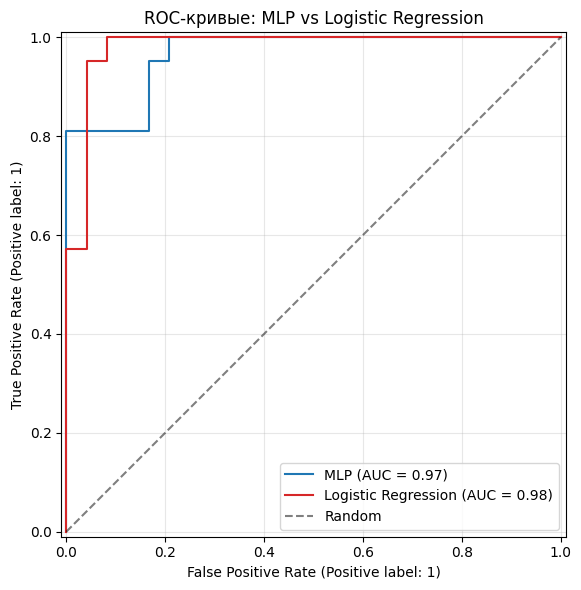

In [ ]:
# Шаг 7. Logistic Regression baseline
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

y_lr_proba = lr_model.predict_proba(X_test)[:, 1]
y_lr_pred  = lr_model.predict(X_test)

print("=== Logistic Regression — Test Metrics ===")
print(f"Accuracy:  {accuracy_score(y_test, y_lr_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_lr_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_lr_pred):.4f}")
print(f"F1:        {f1_score(y_test, y_lr_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_lr_proba):.4f}")

print("\nConfusion Matrix (LR):")
print(confusion_matrix(y_test, y_lr_pred))

# Задание 7.1. ROC-кривые MLP vs LR
fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_predictions(y_test, y_test_proba,
                                 name="MLP", ax=ax, color="tab:blue")
RocCurveDisplay.from_predictions(y_test, y_lr_proba,
                                 name="Logistic Regression", ax=ax, color="tab:red")
ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random")
ax.set_title("ROC-кривые: MLP vs Logistic Regression")
ax.grid(True, alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
# Шаг 8. Сохраняем индексы, чтобы потом посмотреть на «сырые» признаки
from sklearn.model_selection import train_test_split as tts

# Пересоздаём split с индексами
idx_all = np.arange(len(y))
X_tr2, X_tmp2, y_tr2, y_tmp2, idx_tr2, idx_tmp2 = tts(
    X, y, idx_all, test_size=0.30, random_state=42, stratify=y
)
X_val2, X_test2, y_val2, y_test2, idx_val2, idx_test2 = tts(
    X_tmp2, y_tmp2, idx_tmp2, test_size=0.50, random_state=42, stratify=y_tmp2
)

print("idx_test2 (первые 10):", idx_test2[:10])
print("Эти индексы соответствуют строкам raw (после dropna).")

# Переобучаем модели на X_tr2 (та же самая выборка, что при первом split,
# так как random_state фиксирован, но обращаемся к ней через idx_test2)

np.random.seed(42)
model_bonus = MLP(input_size=X_train.shape[1], hidden_size=32, output_size=2, learning_rate=0.05)
train_mlp(model_bonus, X_train, y_train_oh, X_val, y_val, epochs=500, batch_size=32, verbose=False)

lr_bonus = LogisticRegression(max_iter=1000, random_state=42)
lr_bonus.fit(X_train, y_train)

mlp_pred = model_bonus.predict(X_test)
lr_pred  = lr_bonus.predict(X_test)

# Расхождения
disagree = np.where(mlp_pred != lr_pred)[0]
print(f"Модели расходятся на {len(disagree)} из {len(y_test)}")

# Показываем первые 5 случаев
raw_reset = raw.reset_index(drop=True)
for i in disagree[:5]:
    row_idx = idx_test2[i]
    print("=" * 70)
    print(f"Позиция в тесте: {i}, индекс в raw: {row_idx}")
    print(f"MLP pred: {mlp_pred[i]} | proba(болен)={model_bonus.predict_proba(X_test[i:i+1])[0]:.3f}")
    print(f"LR  pred: {lr_pred[i]}  | proba(болен)={lr_bonus.predict_proba(X_test[i:i+1])[0,1]:.3f}")
    print(f"Истина  : {y_test[i]}")
    print("Признаки пациента:")
    print(raw_reset.iloc[row_idx][["age","sex","cp","trestbps","chol","thalach","oldpeak","ca","thal","target"]])

idx_test2 (первые 10): [  3 154 131 218  69  92 112 100 252 278]
Эти индексы соответствуют строкам raw (после dropna).
Модели расходятся на 6 из 45
Позиция в тесте: 12, индекс в raw: 64
MLP pred: 0 | proba(болен)=0.320
LR  pred: 1  | proba(болен)=0.816
Истина  : 1
Признаки пациента:
age          54.0
sex           1.0
cp            4.0
trestbps    120.0
chol        188.0
thalach     113.0
oldpeak       1.4
ca            1.0
thal          7.0
target        1.0
Name: 64, dtype: float64
Позиция в тесте: 21, индекс в raw: 162
MLP pred: 1 | proba(болен)=0.616
LR  pred: 0  | proba(болен)=0.153
Истина  : 0
Признаки пациента:
age          58.0
sex           0.0
cp            4.0
trestbps    100.0
chol        248.0
thalach     122.0
oldpeak       1.0
ca            0.0
thal          3.0
target        0.0
Name: 162, dtype: float64
Позиция в тесте: 22, индекс в raw: 295
MLP pred: 0 | proba(болен)=0.395
LR  pred: 1  | proba(болен)=0.905
Истина  : 1
Признаки пациента:
age          57.0
sex          